# 3.2 Preprocesamiento

> Borrador de la sección 3.2 (Jose). Se integra en `model_development.ipynb`. Cada decisión sigue el formato **Decisión / Alternativas / Por qué / Evidencia**.

**Qué pide el enunciado:** limpieza, faltantes, atípicos, codificación y escalado, todo justificado.

**Cómo está repartido:** lo determinista y fila a fila (fechas, UNSPSC, logaritmos de los montos) está en `src/features.py` (Kevin). Todo lo que se **aprende de los datos** (cuantiles, medianas, codificación, escalado, *target encoding*) está en el `Pipeline` de `src/preprocesamiento.py`, que se ajusta solo con el train y se guarda dentro del modelo. Así no hay fuga y la app aplica exactamente la misma transformación.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=UserWarning)

RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":      # el borrador vive en notebooks/; el notebook final, en la raiz de final-project/
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

from src import config, evaluacion as E, features as F
RES = RAIZ / "resultados"
BASE_V1 = config.DATA_PROCESSED / "v1_A" / "base_contratos.parquet"
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
from src import preprocesamiento as P

base = pd.read_parquet(BASE_V1)
X = F.construir_features(base)
idx_tr, idx_te = E.split_temporal(base, config.ANIO_TEST)
Xtr, ytr = X.loc[idx_tr], base.loc[idx_tr, "y"]
print(f"Base v1: {len(base):,} contratos | train 2019-2023 maduros: {len(idx_tr):,} | test 2024 maduros: {len(idx_te):,}")
print(f"{len(F.FEATURES)} features: {len(F.FEATURES_CAT)} categóricas y {len(F.FEATURES_NUM)} numéricas")

Base v1: 452,494 contratos | train 2019-2023 maduros: 261,249 | test 2024 maduros: 88,088
39 features: 21 categóricas y 18 numéricas


## Faltantes

Se miden en el train. Ninguna fila se borra: los bloques son pequeños y quitarlos sesgaría la muestra.

In [2]:
falt = (Xtr.isna().mean() * 100).round(2)
falt = falt[falt > 0].sort_values(ascending=False).rename("% faltante (train)")
tasa = pd.Series({c: ytr[Xtr[c].isna()].mean() for c in falt.index}, name="tasa de y con faltante")
display(pd.concat([falt, tasa], axis=1))
print(f"Tasa de y en el train: {ytr.mean():.3f}")

,% faltante (train),tasa de y con faltante
dias_firma_a_inicio,1.020,0.000
unspsc_segmento,0.720,0.285
unspsc_familia,0.720,0.285
fin_planeado_cruza_anio,0.110,0.113
p_dur_dias,0.110,0.113


Tasa de y en el train: 0.289


**Decisión:** en los modelos de árboles los faltantes quedan como `NaN` (el HGB los maneja de forma nativa y aprende hacia dónde mandarlos); en kNN y SVM se imputan con la mediana del train y se agrega una columna `<feature>_faltante`. En las categóricas, el faltante es su propia categoría (`SIN_DATO`) en el one-hot o un `NaN` en los códigos ordinales.
- **Alternativas:** borrar filas; imputar 0.
- **Por qué:** imputar 0 confundiría el faltante con "cero respuestas" o "sin lotes", que son valores reales. El indicador conserva la información de que el dato faltaba.
- **Evidencia:** tabla de arriba; todos los faltantes están por debajo del 1,1 % del train. Los contratos sin fecha de inicio no tienen ningún positivo en el train (tasa 0,000): el indicador de faltante es señal, no ruido. [VERIFICADO; causa NO EVALUADA]

## Atípicos: la duración planeada (`p_dur_dias`)

La v1 trae duraciones imposibles (una de 4.078 millones de días) y un 5,2 % de los contratos del train con duración 0.

Máximo en toda la base: 4,078,903,500 días
Duración 0 en el train: 5.2%  |  faltante: 0.11%
Cuantiles de las duraciones > 0 en el train: {0.5: 143.0, 0.9: 330.0, 0.99: 420.0, 0.999: 1259.0}
Tasa de y: duración 0 = 0.253 | duración > 0 = 0.291


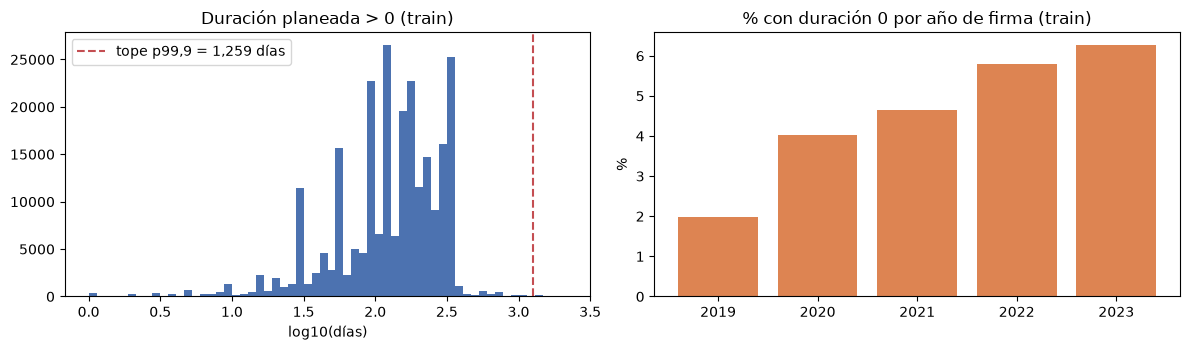

In [3]:
d = X.loc[idx_tr, "p_dur_dias"]
print(f"Máximo en toda la base: {X['p_dur_dias'].max():,.0f} días")
print(f"Duración 0 en el train: {(d == 0).mean():.1%}  |  faltante: {d.isna().mean():.2%}")
print("Cuantiles de las duraciones > 0 en el train:", d[d > 0].quantile([.5, .9, .99, .999]).round(0).to_dict())
y_tr = base.loc[idx_tr, "y"]
print(f"Tasa de y: duración 0 = {y_tr[d == 0].mean():.3f} | duración > 0 = {y_tr[d > 0].mean():.3f}")

prep = P.construir_preprocesador("arbol").fit(Xtr, ytr)
tope = prep.named_transformers_["dur"].tope_[0]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(np.log10(d[d > 0]), bins=60, color="#4C72B0")
ax[0].axvline(np.log10(tope), color="#C44E52", ls="--", label=f"tope p99,9 = {tope:,.0f} días")
ax[0].set_xlabel("log10(días)"); ax[0].set_title("Duración planeada > 0 (train)"); ax[0].legend()
t = base.loc[idx_tr].assign(cero=d.eq(0)).groupby("anio_firma")["cero"].mean() * 100
ax[1].bar(t.index, t.values, color="#DD8452"); ax[1].set_title("% con duración 0 por año de firma (train)"); ax[1].set_ylabel("%")
plt.tight_layout(); plt.show()

**Decisión:** `p_dur_dias = 0` pasa a faltante con el indicador `p_dur_dias_cero`, y las duraciones se recortan por arriba al percentil 99,9 del train.
- **Alternativas:** borrar los contratos; recortar a un tope fijo de 3.650 días (la sugerencia del EDA con la v0); dejar los valores crudos.
- **Por qué:** una duración 0 no es un contrato instantáneo, es un dato sin diligenciar, y se comporta distinto (en el train, tasa de y 0,253 frente a 0,291), así que el indicador le permite al modelo usar esa señal. El tope sale del train, así que es parte del `Pipeline` y no un número escrito a mano. Para el HGB el recorte casi no cambia nada (los árboles cortan por rangos), pero en kNN y SVM un valor de 4.078 millones dominaría la distancia.
- **Evidencia:** gráfica y cifras de arriba.

## Codificación y escalado: un preprocesador por familia de modelo

| | Árboles (HGB, árbol, RF) | Distancia (kNN, SVM) |
|---|---|---|
| Categóricas | códigos ordinales (200 más frecuentes; nuevas y faltantes → `NaN`) | one-hot; categorías con < 1 % del train agrupadas |
| `nit_entidad` (2.330 entidades) | `TargetEncoder` con validación cruzada interna | igual |
| Conteos de competencia | crudos | `log1p` + `RobustScaler` |
| Mes y día de la semana | crudos | seno y coseno |
| Otras numéricas | crudas | mediana + indicador + `RobustScaler` |
| Redundantes (Spearman ≥ 0,995) | se mantienen | se deja una de cada par |
| `p_proveedores_que_manifestaron` | se quita (constante 0) | se quita |

In [4]:
for fam in ("arbol", "distancia"):
    ct = P.construir_preprocesador(fam).fit(Xtr, ytr)
    Z = ct.transform(X.loc[idx_te])
    print(f"{fam:10s}: {Z.shape[1]:3d} columnas de salida | columnas con NaN en 2024: {int(Z.isna().any().sum())}")
te = prep.named_transformers_["entidad"]
print(f"TargetEncoder: {len(te.categories_[0]):,} entidades; las no vistas reciben la media del train ({te.target_mean_:.3f})")

arbol     :  39 columnas de salida | columnas con NaN en 2024: 18


distancia : 158 columnas de salida | columnas con NaN en 2024: 0
TargetEncoder: 2,330 entidades; las no vistas reciben la media del train (0.289)


**Decisión: `TargetEncoder` para la entidad.**
- **Alternativas:** one-hot (2.330 columnas, la mayoría con muy pocos contratos); códigos ordinales (un número arbitrario por entidad).
- **Por qué:** la entidad es la señal más fuerte (H6), pero con muchas categorías. El `TargetEncoder` la resume en la tasa histórica suavizada de la entidad. Dentro del train usa validación cruzada (cada fila se codifica con los otros pliegues), así que el modelo no ve su propia etiqueta; en la búsqueda se vuelve a ajustar en cada fold temporal.
- **Evidencia:** en el SHAP global de la sección 3.6, `nit_entidad` es la feature más importante.

**Decisión: códigos ordinales y no categorías nativas en el HGB.**
- **Alternativas:** categorías nativas del HGB.
- **Por qué:** con categorías nativas `TreeExplainer` da atribuciones incorrectas sin avisar (plan, sección 0 punto 7) y la app se niega a explicar. Con los mismos hiperparámetros las nativas solo ganan +0,003 de PR-AUC en los folds temporales (sección 3.5), menos que la variación entre folds.
- **Evidencia:** sección 3.5, tabla "nativas frente a códigos".

**Decisión: one-hot + escalado robusto solo para kNN y SVM.**
- **Por qué:** los árboles no dependen de la escala ni de transformaciones monótonas; las distancias sí. `RobustScaler` usa mediana y rango intercuartílico, así que los atípicos que quedan no dominan. Los meses son cíclicos: diciembre debe quedar cerca de enero.

## Sin fuga en el preprocesamiento

Lo aprendido (tope de duración, medianas, categorías, codificación de la entidad) depende solo de las filas con las que se ajusta. La prueba `tests/test_preprocesamiento.py::test_ajuste_solo_con_train` lo verifica: cambiar el test no mueve nada de lo aprendido.

In [5]:
otro = X.copy()
otro.loc[idx_te, "p_dur_dias"] = 99999.0
a = P.construir_preprocesador("arbol").fit(X.loc[idx_tr], ytr).named_transformers_["dur"].tope_
b = P.construir_preprocesador("arbol").fit(otro.loc[idx_tr], ytr).named_transformers_["dur"].tope_
print("El tope aprendido no cambia al alterar el test:", np.array_equal(a, b))

El tope aprendido no cambia al alterar el test: True
